# ARTI308 — Machine Learning
## Lab 4 Assignment: Data Quality Assessment & Preprocessing
**Dataset:** Titanic (`titanic(1).csv`)

This notebook follows the five assignment tasks from Lab 4. All analyses use the Titanic dataset; the original dataset is preserved in `df`.

## Setup — Import Libraries and Load Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("titanic(1).csv")
print("Dataset shape:", df.shape)
display(df.head())

ModuleNotFoundError: No module named 'sklearn'

## Task 1 — Identify Data Quality Issues
Check column types, missing values, duplicate records, and numeric ranges. The Titanic dataset does not have the chocolate-sales `Date` or currency-formatted `Amount` columns, so those specific conversions are not applicable.

In [ ]:
print("Data types:")
print(df.dtypes)
print("\nDuplicate rows:", df.duplicated().sum())

quality = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
    "Data Type": df.dtypes.astype(str)
})
display(quality)
display(df.describe(include="all"))

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Duplicate rows: 0


,Missing Count,Missing (%),Data Type
PassengerId,0,0.00,int64
Survived,0,0.00,int64
Pclass,0,0.00,int64
Name,0,0.00,object
Sex,0,0.00,object
Age,177,19.87,float64
SibSp,0,0.00,int64
Parch,0,0.00,int64
Ticket,0,0.00,object
Fare,0,0.00,float64


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,1601,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


**Observation:** The original Titanic dataset has 177 missing `Age` values, 687 missing `Cabin` values, and 2 missing `Embarked` values. `Age` and `Fare` are already numeric. `PassengerId` is an identifier, not a measurement, and `Survived` is the target label. Missingness and potential extreme fares require attention before modeling.

## Task 2 — Apply One Missing-Value Strategy
We use **median imputation** for `Age` because the median is less sensitive to extreme ages than the mean. To keep the data consistent for subsequent analysis, `Embarked` is filled with its most frequent category; `Cabin` is dropped because most entries are missing. These are preprocessing decisions for this exercise, not a claim that missing values are known.

In [ ]:
df_clean = df.copy()
age_median = df_clean["Age"].median()
df_clean["Age"] = df_clean["Age"].fillna(age_median)
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])
df_clean = df_clean.drop(columns=["Cabin"])

print("Age median used:", age_median)
print("Remaining missing values:")
display(df_clean.isna().sum().to_frame("Missing Count"))
print("Shape after handling missing values:", df_clean.shape)

Age median used: 28.0
Remaining missing values:


,Missing Count
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


Shape after handling missing values: (891, 11)


**Explanation:** Median imputation retains passengers rather than deleting rows. We use the mode for the categorical `Embarked` feature and omit `Cabin` because its missingness is substantial. The original `df` remains unchanged.

## Task 3 — Detect and Handle Outliers Using IQR
We inspect `Fare` using a boxplot and calculate the lower and upper fences: **Q1 − 1.5 × IQR** and **Q3 + 1.5 × IQR**. High fares can be legitimate, so we choose **IQR capping** instead of removing passengers.

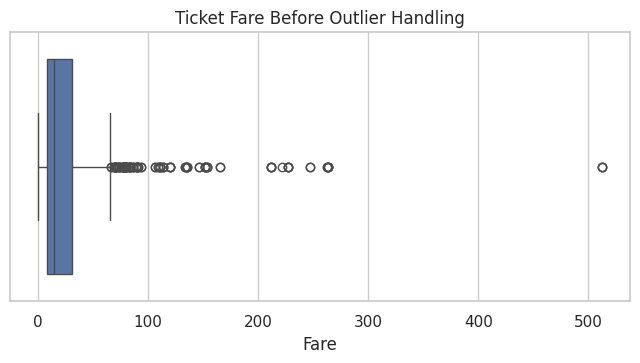

Q1: 7.91, Q3: 31.00, IQR: 23.09
IQR bounds: [-26.72, 65.63]
Outlier count: 116


,PassengerId,Pclass,Fare
1,2,1,71.2833
27,28,1,263.0000
31,32,1,146.5208
34,35,1,82.1708
52,53,1,76.7292
61,62,1,80.0000
62,63,1,83.4750
72,73,2,73.5000
88,89,1,263.0000
102,103,1,77.2875


In [ ]:
plt.figure(figsize=(8, 3.5))
sns.boxplot(x=df_clean["Fare"])
plt.title("Ticket Fare Before Outlier Handling")
plt.xlabel("Fare")
plt.show()

q1 = df_clean["Fare"].quantile(0.25)
q3 = df_clean["Fare"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outlier_mask = (df_clean["Fare"] < lower) | (df_clean["Fare"] > upper)
print(f"Q1: {q1:.2f}, Q3: {q3:.2f}, IQR: {iqr:.2f}")
print(f"IQR bounds: [{lower:.2f}, {upper:.2f}]")
print("Outlier count:", outlier_mask.sum())
display(df_clean.loc[outlier_mask, ["PassengerId", "Pclass", "Fare"]].head(10))

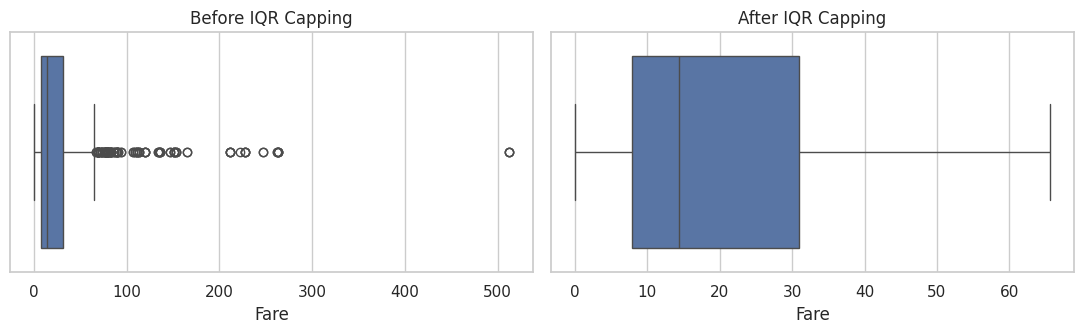

Rows before: 891 | Rows after: 891


In [ ]:
df_processed = df_clean.copy()
df_processed["Fare"] = df_processed["Fare"].clip(lower=lower, upper=upper)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=df_clean["Fare"], ax=axes[0])
axes[0].set_title("Before IQR Capping")
sns.boxplot(x=df_processed["Fare"], ax=axes[1])
axes[1].set_title("After IQR Capping")
plt.tight_layout()
plt.show()
print("Rows before:", len(df_clean), "| Rows after:", len(df_processed))

**Explanation:** Capping replaces values outside the IQR limits with the nearest boundary. This reduces the influence of extreme values while preserving the number of records. A high fare is not necessarily an error, so this is a modeling choice.

## Task 4 — Normalize Numerical Features Using Min-Max and Z-Score
We scale `Age` and `Fare` after missing-value handling and IQR capping. `PassengerId`, `Survived`, and categorical `Pclass` are excluded from these two-feature demonstrations.

In [ ]:
features = ["Age", "Fare"]

minmax_scaler = MinMaxScaler()
df_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(df_processed[features]),
    columns=features, index=df_processed.index
)
print("Min-Max scaled values (0 to 1):")
display(df_minmax.head())
display(df_minmax.agg(["min", "max"]))

Min-Max scaled values (0 to 1):


,Age,Fare
0,0.271174,0.110460
1,0.472229,1.000000
2,0.321438,0.120745
3,0.434531,0.809027
4,0.434531,0.122649


,Age,Fare
min,0.0,0.0
max,1.0,1.0


In [ ]:
standard_scaler = StandardScaler()
df_standardized = pd.DataFrame(
    standard_scaler.fit_transform(df_processed[features]),
    columns=features, index=df_processed.index
)
print("Z-score standardized values:")
display(df_standardized.head())
display(pd.DataFrame({"Mean": df_standardized.mean(), "Std (population)": df_standardized.std(ddof=0)}).round(4))

Z-score standardized values:


,Age,Fare
0,-0.565736,-0.820552
1,0.663861,2.031623
2,-0.258337,-0.787578
3,0.433312,1.419297
4,0.433312,-0.781471


,Mean,Std (population)
Age,0.0,1.0
Fare,0.0,1.0


**Explanation:** Min-Max normalization maps each selected feature to the range 0–1. Z-score standardization centers each feature around zero with a standard deviation of one. The two methods are shown separately for comparison; neither is applied twice to the same features.

## Task 5 — Check Correlation and Apply PCA Only if Appropriate
The lab asks us to apply PCA **only if numerical features show correlation**. We first inspect correlations between `Age` and `Fare`. For this notebook, we define a strong enough linear association as an absolute Pearson correlation of **at least 0.30**. This threshold is an explicit analysis choice, not a rule specified in the lab.

,Age,Fare
Age,1.000000,0.144204
Fare,0.144204,1.000000


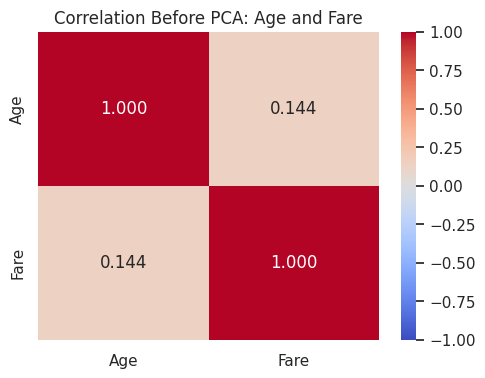

Pearson correlation (Age, Fare): 0.144


In [ ]:
corr = df_standardized[features].corr()
display(corr)
plt.figure(figsize=(5.5, 4))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Before PCA: Age and Fare")
plt.show()

r = corr.loc["Age", "Fare"]
print(f"Pearson correlation (Age, Fare): {r:.3f}")

In [ ]:
threshold = 0.30
if abs(r) >= threshold:
    pca = PCA(n_components=2)
    components = pca.fit_transform(df_standardized[features])
    print("PCA applied: features meet the chosen correlation threshold.")
    print("Explained variance ratios:", pca.explained_variance_ratio_)
    plt.figure(figsize=(7, 5))
    plt.scatter(components[:, 0], components[:, 1], alpha=0.45, s=18)
    plt.title("PCA Projection")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.show()
else:
    print("PCA not applied: Age and Fare have weak linear correlation")
    print(f"(|r| = {abs(r):.3f} < {threshold:.2f}).")
    print("This follows Task 5: apply PCA only when the numerical features show meaningful correlation.")

PCA not applied: Age and Fare have weak linear correlation
(|r| = 0.144 < 0.30).
This follows Task 5: apply PCA only when the numerical features show meaningful correlation.


**Interpretation:** PCA is not automatically required. If the correlation between `Age` and `Fare` is weak, combining them into fewer components is not clearly justified by the lab’s condition. PCA is therefore skipped by the code when the chosen threshold is not met. PCA can still be useful in other contexts, but that is outside this assignment’s conditional instruction.